In [ ]:
import sys
print(sys.executable)

In [2]:
import lightkurve
import pandas as pd
import numpy as np

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [3]:
df = pd.read_csv(r"C:\Users\Anmol\projectLoka\new_data.csv", on_bad_lines='skip')


In [ ]:
display(df.head(20
               ))


In [5]:
print(df.shape)
print(df.info())

(9564, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   kepid              9564 non-null   int64  
 1   kepoi_name         9564 non-null   object 
 2   koi_pdisposition   9564 non-null   object 
 3   koi_score          8054 non-null   float64
 4   koi_fpflag_nt      9564 non-null   int64  
 5   koi_fpflag_ss      9564 non-null   int64  
 6   koi_fpflag_co      9564 non-null   int64  
 7   koi_period         9564 non-null   float64
 8   koi_period_err1    9110 non-null   float64
 9   koi_period_err2    9110 non-null   float64
 10  koi_duration       9564 non-null   float64
 11  koi_duration_err1  9110 non-null   float64
 12  koi_duration_err2  9110 non-null   float64
 13  koi_depth          9201 non-null   float64
 14  koi_depth_err1     9110 non-null   float64
 15  koi_depth_err2     9110 non-null   float64
 16  koi_insol    

Unique target values:
['CANDIDATE' 'FALSE POSITIVE']

Target counts:
koi_pdisposition
FALSE POSITIVE    4847
CANDIDATE         4717
Name: count, dtype: int64

Target percentages:
koi_pdisposition
FALSE POSITIVE    50.68
CANDIDATE         49.32
Name: proportion, dtype: float64


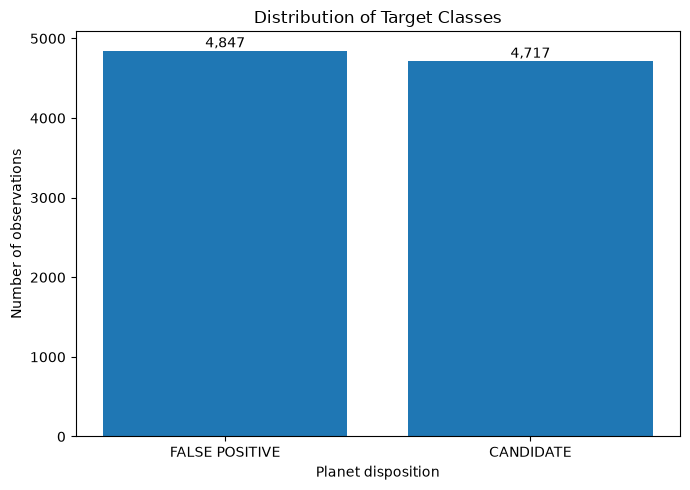

In [7]:
import matplotlib.pyplot as plt

# Target distribution
target_counts = df["koi_pdisposition"].value_counts()

print("Unique target values:")
print(df["koi_pdisposition"].unique())

print("\nTarget counts:")
print(target_counts)

print("\nTarget percentages:")
print(
    df["koi_pdisposition"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Research-style class distribution plot
plt.figure(figsize=(7, 5))

bars = plt.bar(
    target_counts.index,
    target_counts.values
)

plt.title("Distribution of Target Classes")
plt.xlabel("Planet disposition")
plt.ylabel("Number of observations")

# Add count labels
for bar, count in zip(bars, target_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   kepid              9564 non-null   int64  
 1   kepoi_name         9564 non-null   object 
 2   koi_pdisposition   9564 non-null   object 
 3   koi_score          8054 non-null   float64
 4   koi_fpflag_nt      9564 non-null   int64  
 5   koi_fpflag_ss      9564 non-null   int64  
 6   koi_fpflag_co      9564 non-null   int64  
 7   koi_period         9564 non-null   float64
 8   koi_period_err1    9110 non-null   float64
 9   koi_period_err2    9110 non-null   float64
 10  koi_duration       9564 non-null   float64
 11  koi_duration_err1  9110 non-null   float64
 12  koi_duration_err2  9110 non-null   float64
 13  koi_depth          9201 non-null   float64
 14  koi_depth_err1     9110 non-null   float64
 15  koi_depth_err2     9110 non-null   float64
 16  koi_insol          9243 

In [19]:
df = df.drop(columns=[
    "kepid",
    "kepoi_name"
], errors="ignore")


In [20]:
df["target"] = df["koi_pdisposition"].map({
        "CANDIDATE": 1,
        "FALSE POSITIVE": 0
    })

In [21]:
df.head()

,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_period,koi_period_err1,koi_period_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr,target
0,CANDIDATE,1.000,0,0,0,9.488036,2.780000e-05,-2.780000e-05,2.95750,0.08190,-0.08190,616.0,19.5,-19.5,93.59,29.45,-16.65,35.8,1
1,CANDIDATE,0.969,0,0,0,54.418383,2.480000e-04,-2.480000e-04,4.50700,0.11600,-0.11600,875.0,35.5,-35.5,9.11,2.87,-1.62,25.8,1
2,CANDIDATE,0.000,0,0,0,19.899140,1.490000e-05,-1.490000e-05,1.78220,0.03410,-0.03410,10800.0,171.0,-171.0,39.30,31.04,-10.49,76.3,1
3,FALSE POSITIVE,0.000,0,1,0,1.736952,2.630000e-07,-2.630000e-07,2.40641,0.00537,-0.00537,8080.0,12.8,-12.8,891.96,668.95,-230.35,505.6,0
4,CANDIDATE,1.000,0,0,0,2.525592,3.760000e-06,-3.760000e-06,1.65450,0.04200,-0.04200,603.0,16.9,-16.9,926.16,874.33,-314.24,40.9,1


In [40]:
df=df.drop(columns="koi_pdisposition")

In [41]:
df.isnull().sum()

koi_score            0
koi_fpflag_nt        0
koi_fpflag_ss        0
koi_fpflag_co        0
koi_period           0
koi_period_err1      0
koi_period_err2      0
koi_duration         0
koi_duration_err1    0
koi_duration_err2    0
koi_depth            0
koi_depth_err1       0
koi_depth_err2       0
koi_insol            0
koi_insol_err1       0
koi_insol_err2       0
koi_model_snr        0
target               0
dtype: int64

In [42]:
    # Replace missing values with the median of each column
df = df.fillna(df.median(numeric_only=True))

# Check remaining missing values
print(df.isnull().sum())


koi_score            0
koi_fpflag_nt        0
koi_fpflag_ss        0
koi_fpflag_co        0
koi_period           0
koi_period_err1      0
koi_period_err2      0
koi_duration         0
koi_duration_err1    0
koi_duration_err2    0
koi_depth            0
koi_depth_err1       0
koi_depth_err2       0
koi_insol            0
koi_insol_err1       0
koi_insol_err2       0
koi_model_snr        0
target               0
dtype: int64


In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

features = df.drop(columns=[
    "kepid", "kep, "koi_pdisposition",
    "koi_score", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co"
])

plt.figure(figsize=(12, 8))
sns.heatmap(features.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

SyntaxError: unterminated string literal (detected at line 5) (3961986492.py, line 5)

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   koi_score          9564 non-null   float64
 1   koi_fpflag_nt      9564 non-null   int64  
 2   koi_fpflag_ss      9564 non-null   int64  
 3   koi_fpflag_co      9564 non-null   int64  
 4   koi_period         9564 non-null   float64
 5   koi_period_err1    9564 non-null   float64
 6   koi_period_err2    9564 non-null   float64
 7   koi_duration       9564 non-null   float64
 8   koi_duration_err1  9564 non-null   float64
 9   koi_duration_err2  9564 non-null   float64
 10  koi_depth          9564 non-null   float64
 11  koi_depth_err1     9564 non-null   float64
 12  koi_depth_err2     9564 non-null   float64
 13  koi_insol          9564 non-null   float64
 14  koi_insol_err1     9564 non-null   float64
 15  koi_insol_err2     9564 non-null   float64
 16  koi_model_snr      9564 

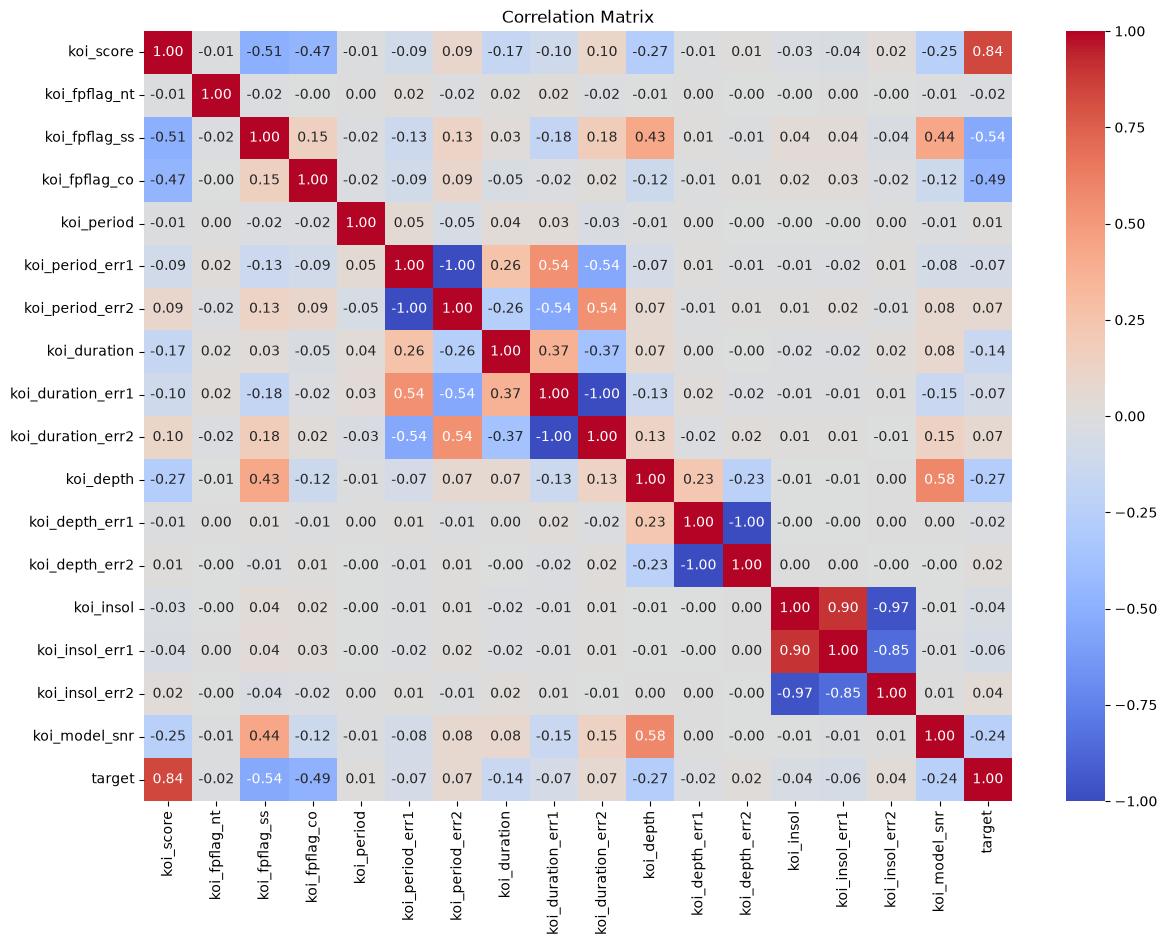

In [45]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [46]:
# Remove leakage-prone features and highly redundant features
df = df.drop(columns=[
    # Leakage-prone / target-derived features
    "koi_score", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co",

    # Highly redundant features (|correlation| ≈ 1)
    "koi_period_err2",
    "koi_duration_err2",
    "koi_depth_err2",
    "koi_insol_err1",
    "koi_insol_err2"
])

print(df.columns)

Index(['koi_period', 'koi_period_err1', 'koi_duration', 'koi_duration_err1',
       'koi_depth', 'koi_depth_err1', 'koi_insol', 'koi_model_snr', 'target'],
      dtype='object')


In [48]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(7651, 8) (1913, 8)


In [49]:
from sklearn.preprocessing import PowerTransformer, StandardScaler

pt = PowerTransformer(method="yeo-johnson")
scaler = StandardScaler()

X_train = pt.fit_transform(X_train)
X_test = pt.transform(X_test)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(7651, 8) (1913, 8)


In [50]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print(X_train.shape, X_val.shape, X_test.shape)

(6120, 8) (1531, 8) (1913, 8)


In [59]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet = TabNetClassifier(
    n_d=24,
    n_a=24,
    n_steps=5,
    gamma=1.3,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=0.02),
    mask_type="entmax",
    seed=42,
    device_name="cuda",
    verbose=10
)

tabnet.fit(
    X_train, y_train.values,
    eval_set=[(X_val, y_val.values)],
    eval_name=["validation"],
    eval_metric=["auc"],
    max_epochs=150,
    patience=25,
    batch_size=256,
    virtual_batch_size=128
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.64048 | validation_auc: 0.76316 |  0:00:08s
epoch 10 | loss: 0.4065  | validation_auc: 0.8731  |  0:00:57s
epoch 20 | loss: 0.37516 | validation_auc: 0.88457 |  0:01:49s
epoch 30 | loss: 0.35616 | validation_auc: 0.89269 |  0:02:24s
epoch 40 | loss: 0.3563  | validation_auc: 0.88941 |  0:02:55s
epoch 50 | loss: 0.35002 | validation_auc: 0.89795 |  0:03:25s
epoch 60 | loss: 0.3497  | validation_auc: 0.89983 |  0:03:56s
epoch 70 | loss: 0.33604 | validation_auc: 0.9032  |  0:04:25s
epoch 80 | loss: 0.33551 | validation_auc: 0.89917 |  0:04:56s
epoch 90 | loss: 0.31909 | validation_auc: 0.89381 |  0:05:26s

Early stopping occurred at epoch 99 with best_epoch = 74 and best_validation_auc = 0.90569


C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [60]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_pred = tabnet.predict(X_test)
y_prob = tabnet.predict_proba(X_test)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 0.8301097752221641
Precision: 0.8759124087591241
Recall   : 0.7635206786850477
F1 Score : 0.8158640226628895
ROC-AUC  : 0.9207256944824042


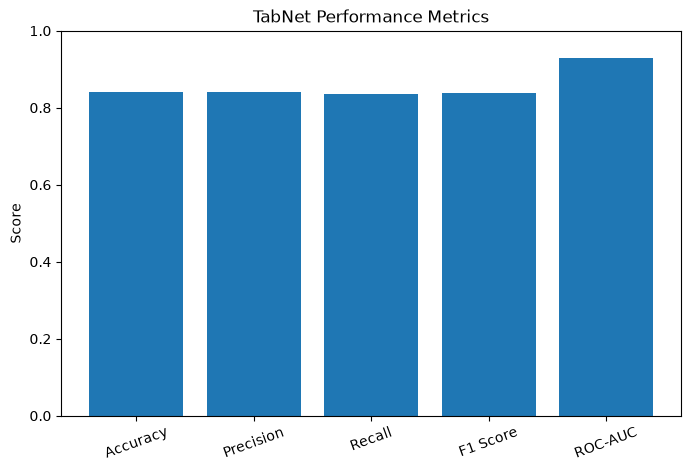

In [61]:
import matplotlib.pyplot as plt

metrics = {
    "Accuracy": 0.8406,
    "Precision": 0.8401,
    "Recall": 0.8356,
    "F1 Score": 0.8379,
    "ROC-AUC": 0.9302
}

plt.figure(figsize=(8, 5))
plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("TabNet Performance Metrics")
plt.xticks(rotation=20)
plt.show()

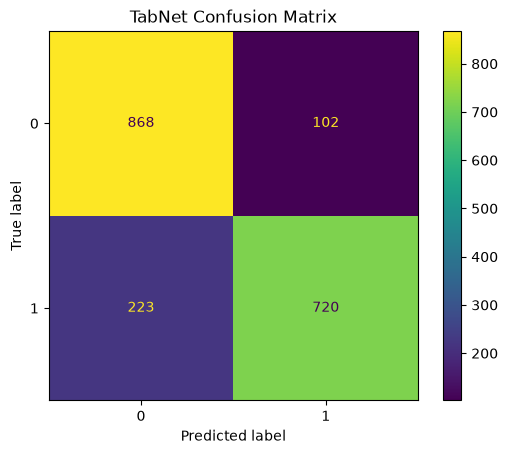

In [62]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("TabNet Confusion Matrix")
plt.show()

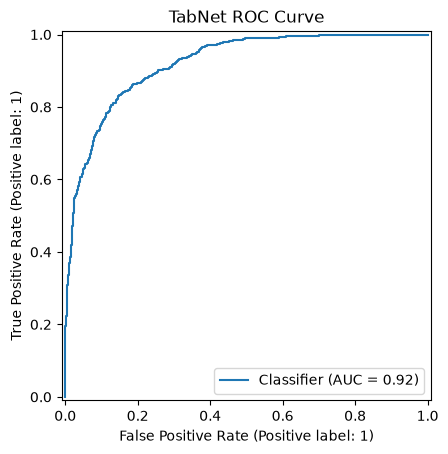

In [63]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title("TabNet ROC Curve")
plt.show()

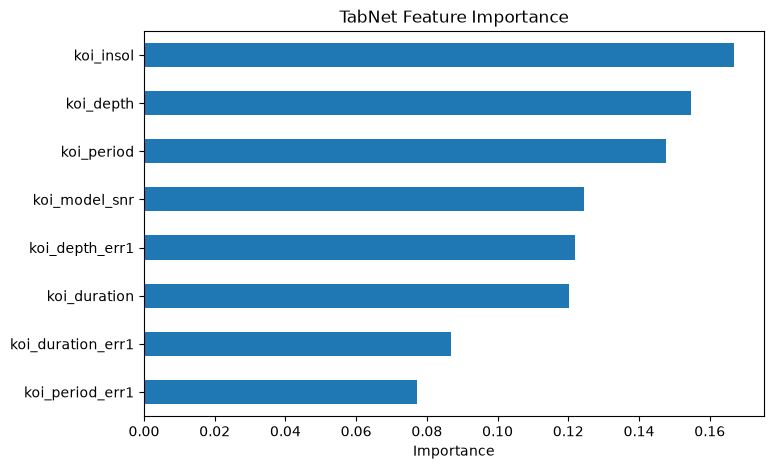

In [64]:
importance = pd.Series(
    tabnet.feature_importances_,
    index=[
        "koi_period",
        "koi_period_err1",
        "koi_duration",
        "koi_duration_err1",
        "koi_depth",
        "koi_depth_err1",
        "koi_insol",
        "koi_model_snr"
    ]
).sort_values(ascending=True)

importance.plot(kind="barh", figsize=(8, 5))
plt.xlabel("Importance")
plt.title("TabNet Feature Importance")
plt.show()

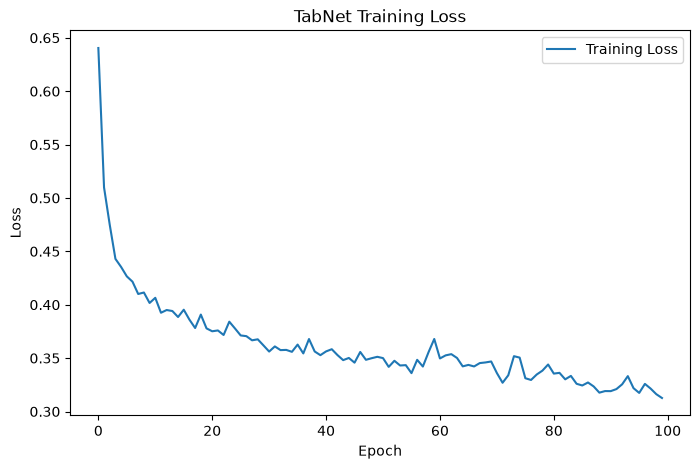

In [65]:
plt.figure(figsize=(8, 5))

plt.plot(tabnet.history["loss"], label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("TabNet Training Loss")
plt.legend()
plt.show()

In [66]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["False Positive", "Candidate"]
))

                precision    recall  f1-score   support

False Positive       0.80      0.89      0.84       970
     Candidate       0.88      0.76      0.82       943

      accuracy                           0.83      1913
     macro avg       0.84      0.83      0.83      1913
  weighted avg       0.84      0.83      0.83      1913



In [67]:
tabnet.save_model("kepler_tabnet_model")

Successfully saved model at kepler_tabnet_model.zip


'kepler_tabnet_model.zip'

In [68]:
import joblib

joblib.dump(pt, "yeo_johnson.pkl")
joblib.dump(scaler, "scaler.pkl")

print("Model and preprocessing saved successfully.")

Model and preprocessing saved successfully.


In [73]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("Original features:", X_train.shape[1])
print("PCA features:", X_train_pca.shape[1])
print("Explained variance:", pca.explained_variance_ratio_.sum())

Original features: 8
PCA features: 5
Explained variance: 0.9707550307482355


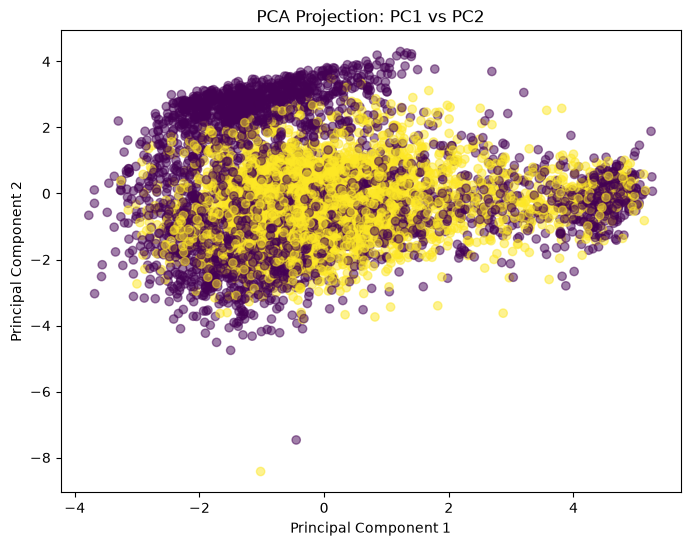

In [74]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    alpha=0.5
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection: PC1 vs PC2")
plt.show()

In [75]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total variance explained:",
      pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.42384481 0.31732715 0.11584869 0.07281909 0.0409153 ]
Total variance explained: 0.9707550307482355


In [76]:
from pytorch_tabnet.tab_model import TabNetClassifier
import torch

tabnet_pca = TabNetClassifier(
    n_d=24,
    n_a=24,
    n_steps=5,
    gamma=1.3,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=0.02),
    mask_type="entmax",
    seed=42,
    device_name="cuda",
    verbose=10
)

tabnet_pca.fit(
    X_train_pca, y_train.values,
    eval_set=[(X_val_pca, y_val.values)],
    eval_name=["validation"],
    eval_metric=["auc"],
    max_epochs=150,
    patience=25,
    batch_size=256,
    virtual_batch_size=128
)

C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cuda
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 0.72212 | validation_auc: 0.78902 |  0:00:02s
epoch 10 | loss: 0.43378 | validation_auc: 0.86611 |  0:00:31s
epoch 20 | loss: 0.44163 | validation_auc: 0.86261 |  0:01:00s
epoch 30 | loss: 0.42518 | validation_auc: 0.86167 |  0:01:27s
epoch 40 | loss: 0.4251  | validation_auc: 0.85803 |  0:01:55s
epoch 50 | loss: 0.41825 | validation_auc: 0.8612  |  0:02:25s
epoch 60 | loss: 0.41335 | validation_auc: 0.86247 |  0:02:53s
epoch 70 | loss: 0.40347 | validation_auc: 0.85583 |  0:03:26s

Early stopping occurred at epoch 76 with best_epoch = 51 and best_validation_auc = 0.86893


C:\Users\Anmol\projectLoka\.venv\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


In [77]:


from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_pred_pca = tabnet_pca.predict(X_test_pca)
y_prob_pca = tabnet_pca.predict_proba(X_test_pca)[:, 1]

print("Accuracy :", accuracy_score(y_test, y_pred_pca))
print("Precision:", precision_score(y_test, y_pred_pca))
print("Recall   :", recall_score(y_test, y_pred_pca))
print("F1 Score :", f1_score(y_test, y_pred_pca))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob_pca))

Accuracy : 0.8029273392577104
Precision: 0.7596330275229358
Recall   : 0.8780487804878049
F1 Score : 0.8145597638957206
ROC-AUC  : 0.8941620841578206


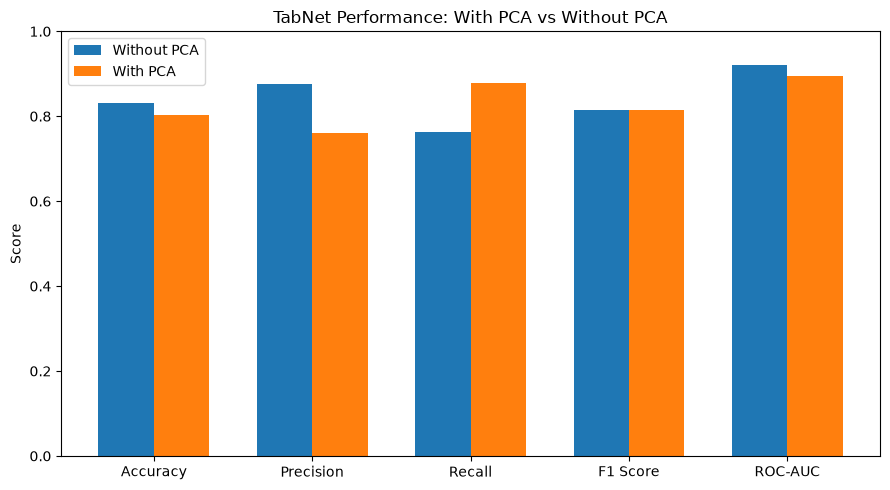

In [78]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

without_pca = [0.8301, 0.8759, 0.7635, 0.8159, 0.9207]
with_pca = [0.8029, 0.7596, 0.8780, 0.8146, 0.8942]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, without_pca, width, label="Without PCA")
plt.bar(x + width/2, with_pca, width, label="With PCA")

plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0, 1)
plt.title("TabNet Performance: With PCA vs Without PCA")
plt.legend()

plt.tight_layout()
plt.show()